# AI 1 · Phase 1.0 — go/no-go checks on the MBTA arrival/departure data
Decides whether the MBTA records are good enough to train the real-world speed model (AI 1).

| # | Check | Go if |
|---|---|---|
| 1 | Same columns in every monthly file, `actual` present | yes |
| 2 | Coverage: share of rows with an `actual` time, per route and month | most rows/trips covered |
| 3 | IDs and times match the GTFS timetable valid that day | high match rate |
| 4 | 5 routes: scheduled vs. actual segment times by hour | a meaningful gap at least at some hours |

What we already know about the data:
- MBTA data dictionary: `scheduled` = time the trip was scheduled to **depart** the timepoint,
  `actual` = time it actually **departed**. Service dates run from about 02:00 to 01:59 the next day.
- Times are **local Boston time** on the dummy date 1900-01-01 (the `Z` suffix is not UTC); after midnight they are
  on 1900-01-02, so *seconds since 1900-01-01 00:00* = seconds into the service day. (Check 3 tests this.)
- `stop_id` = GTFS `stop_id`. `route_id` = GTFS `route_id` without leading zeros (`01` → `1`),
  except Silver Line / CT routes, which use the GTFS `route_short_name` (`SL1` → `741`).
- `half_trip_id` is **not** the GTFS `trip_id`; rows are matched to GTFS by route + direction + stop + scheduled time.
- Direction: `Outbound` = GTFS `direction_id` 0, `Inbound` = 1.

## Setup
**Kaggle:** *Add Input* → your MBTA arrival/departure dataset. The notebook searches `/kaggle/input` and accepts
the monthly CSVs or the yearly zips (`MBTA_Bus_Arrival_Departure_Times_YYYY.zip`), whatever the dataset is called.
The GTFS feed `20240313` is taken from the inputs if present, otherwise downloaded (needs Settings → Internet on).

**Locally:** reads `data/raw/`, writes to `data/interim/phase1_0/`.

Memory: files are processed **one month at a time**; only small summaries and the 5-route segments are kept.

In [1]:
from pathlib import Path
import gc, io, re, time, zipfile, urllib.request
import polars as pl
import matplotlib.pyplot as plt
print("polars", pl.__version__)  # tested with polars 1.9 and 2.0

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    INPUT, OUT = Path("/kaggle/input"), Path("/kaggle/working/phase1_0")
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
    INPUT, OUT = ROOT / "data" / "raw", ROOT / "data" / "interim" / "phase1_0"
OUT.mkdir(parents=True, exist_ok=True)

SAMPLE_ROUTES = ["01", "28", "39", "66", "111"]  # as written in the arrival data
GTFS_FEED = "20240313"                           # archive feed valid on the check-3 sample day
SAMPLE_DAY = "2024-03-13"

# Find every month, as a plain CSV or as a CSV inside a yearly zip (CSV wins if both exist)
FILE_RE = re.compile(r"MBTA-Bus-Arrival-Departure-Times_(\d{4}-\d{2})\.csv$")
sources = {}
for z in sorted(INPUT.rglob("*.zip")):
    try:
        for name in zipfile.ZipFile(z).namelist():
            if m := FILE_RE.search(name):
                sources[m.group(1)] = ("zip", z, name)
    except zipfile.BadZipFile:
        pass
for f in sorted(INPUT.rglob("*.csv")):
    if m := FILE_RE.search(f.name):
        sources[m.group(1)] = ("csv", f, None)
sources = dict(sorted(sources.items()))
assert sources, f"No MBTA-Bus-Arrival-Departure-Times_YYYY-MM.csv files (or zips containing them) under {INPUT}"
MONTHS = list(sources)
print(f"{len(MONTHS)} months: {MONTHS[0]} -> {MONTHS[-1]}  "
      f"({sum(s[0] == 'csv' for s in sources.values())} CSV files, {sum(s[0] == 'zip' for s in sources.values())} inside zips)")

def open_month(month):
    """File path or bytes for one month, ready for pl.read_csv."""
    kind, path, member = sources[month]
    return path if kind == "csv" else zipfile.ZipFile(path).read(member)

def header_of(month):
    kind, path, member = sources[month]
    raw = open(path, "rb").readline() if kind == "csv" else zipfile.ZipFile(path).open(member).readline()
    return [c.strip().strip('"') for c in raw.decode("utf-8-sig").strip().split(",")]

polars 1.35.2
48 months: 2022-01 -> 2025-12  (48 CSV files, 0 inside zips)


## Check 1 — schema of every file

In [2]:
EXPECTED = ["service_date", "route_id", "direction_id", "half_trip_id", "stop_id", "time_point_id",
            "time_point_order", "point_type", "standard_type", "scheduled", "actual",
            "scheduled_headway", "headway"]
bad = {m: h for m in MONTHS if (h := header_of(m)) != EXPECTED}
print("All files have the expected 13 columns" if not bad else f"Months with different columns: {bad}")

All files have the expected 13 columns


## One pass over all months
For each month: coverage numbers for every route, timepoint-to-timepoint segments for the 5 sample routes,
and (for March 2024) the rows of the check-3 sample day. Results are saved as Parquet in the output folder,
so re-running the notebook skips this step. Delete the folder to recompute.

In [3]:
COV_PATH = OUT / "coverage_route_month.parquet"
SEG_PATH = OUT / "sample_segments.parquet"
DAY_PATH = OUT / f"rows_{SAMPLE_DAY}.parquet"
USE_COLS = EXPECTED[:11]  # headway columns are not needed

# The time format changes between years: "1900-01-01 06:05:00.000" (2022) vs "1900-01-01T06:05:00Z" (later)
def seconds_of_day(col):
    ts = (pl.col(col).str.replace("T", " ").str.replace("Z", "").str.slice(0, 19)
          .str.strptime(pl.Datetime, "%Y-%m-%d %H:%M:%S", strict=False))
    return (ts - pl.datetime(1900, 1, 1)).dt.total_seconds().cast(pl.Int32)

def read_month(month):
    d = pl.read_csv(open_month(month), columns=USE_COLS, infer_schema=False, null_values=["NA", ""])
    return (d.with_columns(sched_s=seconds_of_day("scheduled"), act_s=seconds_of_day("actual"),
                           time_point_order=pl.col("time_point_order").cast(pl.Int16))
             .with_columns(bad_time=(pl.col("sched_s").is_null() & pl.col("scheduled").is_not_null()))
             .drop("scheduled", "actual"))

TRIP = ["service_date", "half_trip_id"]

def coverage_of(d, month):
    trips = (d.group_by("route_id", *TRIP).agg(full=pl.col("act_s").is_not_null().all())
              .group_by("route_id").agg(trips=pl.len(), trips_full=pl.col("full").sum()))
    return (d.group_by("route_id")
             .agg(rows=pl.len(), rows_actual=pl.col("act_s").is_not_null().sum(),
                  rows_bad_time=pl.col("bad_time").sum(),
                  headway_rows=(pl.col("standard_type") == "Headway").sum())
             .join(trips, on="route_id")
             .with_columns(month=pl.lit(month)))

def segments_of(d):
    """Pair consecutive timepoints of each trip into segments (one row per trip per segment)."""
    return (d.filter(pl.col("half_trip_id").is_not_null())
             .unique(subset=TRIP + ["time_point_order"], keep="first")
             .sort(TRIP + ["time_point_order"])
             .with_columns(to_tp=pl.col("time_point_id").shift(-1).over(TRIP),
                           sched_end=pl.col("sched_s").shift(-1).over(TRIP),
                           act_end=pl.col("act_s").shift(-1).over(TRIP))
             .filter(pl.col("to_tp").is_not_null())
             .with_columns(date=pl.col("service_date").str.to_date())
             .select("route_id", "direction_id", "date", "half_trip_id",
                     from_tp="time_point_id", to_tp="to_tp",
                     hour=((pl.col("sched_s") // 3600) % 24).cast(pl.Int8),
                     sched_run=pl.col("sched_end") - pl.col("sched_s"),
                     act_run=pl.col("act_end") - pl.col("act_s")))

if COV_PATH.exists() and SEG_PATH.exists() and DAY_PATH.exists():
    print("Loading cached results from", OUT)
else:
    t0, cov_parts, seg_parts = time.time(), [], []
    for i, month in enumerate(MONTHS, 1):
        d = read_month(month)
        cov_parts.append(coverage_of(d, month))
        seg_parts.append(segments_of(d.filter(pl.col("route_id").is_in(SAMPLE_ROUTES))))
        if month == SAMPLE_DAY[:7]:
            d.filter(pl.col("service_date") == SAMPLE_DAY).write_parquet(DAY_PATH)
        del d; gc.collect()
        print(f"\r{i}/{len(MONTHS)}  {month}  ({time.time() - t0:.0f}s)", end="")
    pl.concat(cov_parts).write_parquet(COV_PATH)
    pl.concat(seg_parts).write_parquet(SEG_PATH)
    print(f"\nDone in {time.time() - t0:.0f}s")

coverage = pl.read_parquet(COV_PATH)
print(f"Total rows: {coverage['rows'].sum():,}")
assert coverage["rows_bad_time"].sum() == 0, "some time strings failed to parse"

48/48  2025-12  (123s)
Done in 125s
Total rows: 110,683,890


## Check 2 — coverage of `actual`
- **Row coverage**: share of timepoint rows that have an actual time.
- **Full-trip coverage**: share of trips where *every* timepoint has an actual time.
  A segment needs actual times at both ends, so this is the stricter number.

Overall row coverage:       93.0%
Overall full-trip coverage: 82.2%
Worst month (rows):  2023-06  89.5%


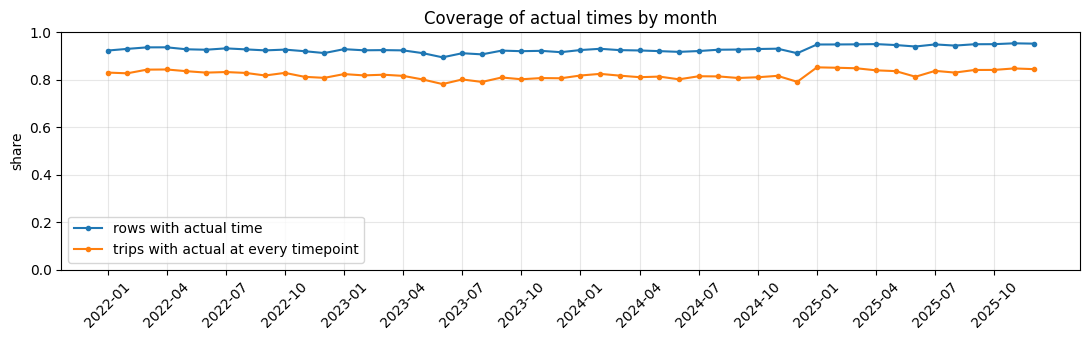

In [4]:
by_month = (coverage.group_by("month").agg(pl.col("rows", "rows_actual", "trips", "trips_full").sum())
            .with_columns(row_cov=pl.col("rows_actual") / pl.col("rows"),
                          trip_full_cov=pl.col("trips_full") / pl.col("trips"))
            .sort("month"))
total = by_month.select(pl.col("rows", "rows_actual", "trips", "trips_full").sum())
print(f"Overall row coverage:       {total['rows_actual'][0] / total['rows'][0]:.1%}")
print(f"Overall full-trip coverage: {total['trips_full'][0] / total['trips'][0]:.1%}")
print(f"Worst month (rows):  {by_month.sort('row_cov')['month'][0]}  {by_month['row_cov'].min():.1%}")

fig, ax = plt.subplots(figsize=(11, 3.5))
x = list(range(by_month.height))
ax.plot(x, by_month["row_cov"], marker=".", label="rows with actual time")
ax.plot(x, by_month["trip_full_cov"], marker=".", label="trips with actual at every timepoint")
step = max(1, len(x) // 16)
ax.set_xticks(x[::step], by_month["month"].to_list()[::step], rotation=45)
ax.set_ylim(0, 1); ax.set_ylabel("share"); ax.grid(alpha=.3); ax.legend(loc="lower left")
ax.set_title("Coverage of actual times by month")
plt.tight_layout(); plt.show()

In [5]:
by_route = (coverage.group_by("route_id").agg(pl.col("rows", "rows_actual", "trips", "trips_full").sum(),
                                              months=pl.col("month").n_unique())
            .with_columns(row_cov=pl.col("rows_actual") / pl.col("rows"),
                          trip_full_cov=pl.col("trips_full") / pl.col("trips"))
            .sort("row_cov"))
print(f"{by_route.height} routes. Row coverage per route: median {by_route['row_cov'].median():.1%}, "
      f"routes below 80%: {(by_route['row_cov'] < 0.8).sum()}")
print("Lowest-coverage routes:")
by_route.head(10).select("route_id", "months", "rows", "row_cov", "trip_full_cov")

158 routes. Row coverage per route: median 95.2%, routes below 80%: 10
Lowest-coverage routes:


route_id,months,rows,row_cov,trip_full_cov
str,u32,u32,f64,f64
"""600""",16,5880,0.047109,0.009768
"""rad""",9,1046,0.296367,0.292543
"""746_""",48,534319,0.431654,0.206286
"""SL2""",48,1320509,0.692744,0.413505
"""8007""",4,26953,0.716952,0.391291
"""SL1""",48,2861532,0.74424,0.372156
"""171""",48,17532,0.750171,0.185274
"""553""",48,178880,0.76406,0.235407
"""7001""",5,924,0.765152,0.616883


## Check 3 — match to the GTFS timetable valid on the same day
One sample day (Wednesday 13 March 2024) against archive feed `20240313.zip`.
A row matches if a GTFS trip active that day serves the same route, direction and stop at exactly the scheduled time.

In [6]:
def find_gtfs(feed):
    """GTFS feed from the inputs (zip, or a folder if Kaggle unzipped it), else download it."""
    for z in INPUT.rglob(f"{feed}.zip"):
        return zipfile.ZipFile(z)
    for st in INPUT.rglob("stop_times.txt"):
        if feed in str(st.parent):
            return st.parent
    target = OUT / f"{feed}.zip"
    if not target.exists():
        print(f"Downloading GTFS feed {feed} ...")
        urllib.request.urlretrieve(f"https://cdn.mbtace.com/archive/{feed}.zip", target)
    return zipfile.ZipFile(target)

FEED = find_gtfs(GTFS_FEED)
print("GTFS source:", getattr(FEED, "filename", FEED))

def gtfs(name):
    raw = FEED.read(name) if isinstance(FEED, zipfile.ZipFile) else (FEED / name).read_bytes()
    return pl.read_csv(io.BytesIO(raw), infer_schema=False)

def gtfs_seconds(col):  # "25:10:00" -> 90600
    p = pl.col(col).str.split(":")
    return (p.list.get(0).cast(pl.Int32) * 3600 + p.list.get(1).cast(pl.Int32) * 60 + p.list.get(2).cast(pl.Int32))

def active_services(day):
    ymd = day.replace("-", "")
    dow = pl.Series([day]).str.to_date().dt.strftime("%A").str.to_lowercase()[0]
    cal, cd = gtfs("calendar.txt"), gtfs("calendar_dates.txt")
    s = set(cal.filter((pl.col("start_date") <= ymd) & (pl.col("end_date") >= ymd) & (pl.col(dow) == "1"))["service_id"])
    s |= set(cd.filter((pl.col("date") == ymd) & (pl.col("exception_type") == "1"))["service_id"])
    return s - set(cd.filter((pl.col("date") == ymd) & (pl.col("exception_type") == "2"))["service_id"])

routes = gtfs("routes.txt")
# arrival route_id -> GTFS route_id: strip leading zeros, else look up route_short_name (SL1 -> 741)
short_to_id = dict(zip(routes["route_short_name"], routes["route_id"]))
gtfs_ids = set(routes["route_id"])
to_gtfs_route = lambda r: (r.lstrip("0") if r.lstrip("0") in gtfs_ids else short_to_id.get(r))

trips = gtfs("trips.txt").filter(pl.col("service_id").is_in(list(active_services(SAMPLE_DAY))))
stop_times = (gtfs("stop_times.txt")
              .join(trips.select("trip_id", "route_id", "direction_id"), on="trip_id")
              .select(gtfs_route="route_id", stop_id="stop_id",
                      direction=pl.when(pl.col("direction_id") == "1").then(pl.lit("Inbound")).otherwise(pl.lit("Outbound")),
                      sched_s=gtfs_seconds("departure_time"))
              .unique())

KEY = ["gtfs_route", "direction", "stop_id", "sched_s"]
day = (pl.read_parquet(DAY_PATH)
       .with_columns(gtfs_route=pl.col("route_id").map_elements(to_gtfs_route, return_dtype=pl.String),
                     direction=pl.col("direction_id")))
match_rate = lambda df: df.join(stop_times, on=KEY, how="semi").height / df.height

print(f"{SAMPLE_DAY}: {day.height:,} rows, {day['half_trip_id'].n_unique():,} trips")
print(f"  stop_id found in GTFS stops.txt:          {day['stop_id'].is_in(gtfs('stops.txt')['stop_id'].to_list()).mean():.1%}")
print(f"  route_id mapped to a GTFS route:          {day['gtfs_route'].is_not_null().mean():.1%}  "
      f"unmapped: {sorted(day.filter(pl.col('gtfs_route').is_null())['route_id'].unique().to_list())}")
print(f"  row matches a GTFS trip at the same time: {match_rate(day):.1%}")
# Time zone test: if the "Z" really meant UTC, shifting by the Eastern offset (4 h in March) would raise the match rate
for h in (-4, 4):
    print(f"  ...same check with times shifted {h:+d} h:  {match_rate(day.with_columns(sched_s=pl.col('sched_s') + h * 3600)):.1%}")

GTFS source: /kaggle/input/datasets/omarhazemahmed/20240313-gtfs
2024-03-13: 83,458 rows, 11,903 trips
  stop_id found in GTFS stops.txt:          97.9%
  route_id mapped to a GTFS route:          99.4%  unmapped: ['191', '192', '193', '194', '746_']
  row matches a GTFS trip at the same time: 96.6%
  ...same check with times shifted -4 h:  5.9%
  ...same check with times shifted +4 h:  5.8%


## Check 4 — scheduled vs. actual segment times on 5 routes
A **segment** joins two consecutive timepoints of the same trip.
`speed_factor = scheduled run time ÷ actual run time` (the distance cancels, so GTFS shapes aren't needed yet).
1 = on timetable, below 1 = slower than the timetable, above 1 = faster.
Only a loose sanity filter here (factor 0.2–5); distance-based cleaning (2–80 km/h, ≥100 m) is Phase 1.1.

In [7]:
seg = pl.read_parquet(SEG_PATH)
n_all = seg.height
seg_ok = seg.filter(pl.col("act_run").is_not_null())
n_actual = seg_ok.height
seg_ok = seg_ok.filter((pl.col("sched_run") > 0) & (pl.col("act_run") > 0))
n_pos = seg_ok.height
seg_ok = (seg_ok.with_columns(factor=pl.col("sched_run") / pl.col("act_run"))
                .filter(pl.col("factor").is_between(0.2, 5))
                .with_columns(day_type=pl.when(pl.col("date").dt.weekday() <= 5).then(pl.lit("Weekday"))
                                         .when(pl.col("date").dt.weekday() == 6).then(pl.lit("Saturday"))
                                         .otherwise(pl.lit("Sunday")),
                              year=pl.col("date").dt.year()))
print(f"Segments: {n_all:,} | with actual at both ends: {n_actual:,} ({n_actual / n_all:.1%}) | "
      f"positive times: {n_pos:,} | factor 0.2–5: {seg_ok.height:,} ({seg_ok.height / n_all:.1%} kept)")

Segments: 14,518,543 | with actual at both ends: 13,384,175 (92.2%) | positive times: 13,375,553 | factor 0.2–5: 13,141,072 (90.5% kept)


In [8]:
summary = (seg_ok.group_by("route_id").agg(
               segments=pl.len(),
               median_factor=pl.col("factor").median(),
               share_off_10pct=((pl.col("factor") - 1).abs() > 0.10).mean(),
               mae_timetable_s=(pl.col("act_run") - pl.col("sched_run")).abs().mean(),
               mean_sched_run_s=pl.col("sched_run").mean())
           .sort("route_id"))
print("Timetable (B0) error per segment: how far actual run times are from scheduled")
summary

Timetable (B0) error per segment: how far actual run times are from scheduled


route_id,segments,median_factor,share_off_10pct,mae_timetable_s,mean_sched_run_s
str,u32,f64,f64,f64,f64
"""01""",2022107,0.946372,0.770095,77.865642,262.722536
"""111""",4156563,1.0,0.819917,61.860242,171.237506
"""28""",2611203,0.983607,0.799033,78.929779,244.085335
"""39""",2155423,1.0,0.785149,67.580321,224.15665
"""66""",2195776,0.967742,0.768743,113.16446,348.188057


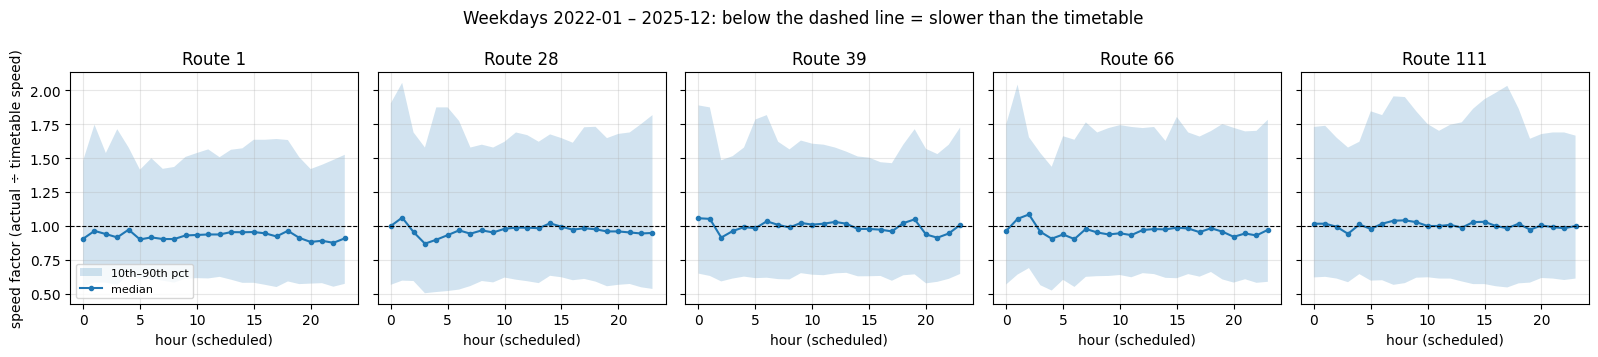

In [9]:
wk = seg_ok.filter(pl.col("day_type") == "Weekday")
by_hour = (wk.group_by("route_id", "hour").agg(p50=pl.col("factor").median(),
                                              p10=pl.col("factor").quantile(0.10),
                                              p90=pl.col("factor").quantile(0.90), n=pl.len())
           .filter(pl.col("n") >= 200).sort("route_id", "hour"))

fig, axes = plt.subplots(1, len(SAMPLE_ROUTES), figsize=(16, 3.6), sharey=True)
for ax, r in zip(axes, SAMPLE_ROUTES):
    d = by_hour.filter(pl.col("route_id") == r)
    ax.fill_between(d["hour"], d["p10"], d["p90"], alpha=.2, label="10th–90th pct")
    ax.plot(d["hour"], d["p50"], marker=".", label="median")
    ax.axhline(1, color="k", lw=.8, ls="--")
    ax.set_title(f"Route {r.lstrip('0')}"); ax.set_xlabel("hour (scheduled)"); ax.grid(alpha=.3)
axes[0].set_ylabel("speed factor (actual ÷ timetable speed)")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"Weekdays {MONTHS[0]} – {MONTHS[-1]}: below the dashed line = slower than the timetable")
plt.tight_layout(); plt.show()

In [10]:
# Median weekday factor per route: AM peak, midday, PM peak
period = (pl.when(pl.col("hour").is_between(7, 9)).then(pl.lit("1 AM peak 7–9"))
            .when(pl.col("hour").is_between(10, 14)).then(pl.lit("2 midday 10–14"))
            .when(pl.col("hour").is_between(15, 18)).then(pl.lit("3 PM peak 15–18")).otherwise(pl.lit("other")))
(wk.with_columns(period=period).filter(pl.col("period") != "other")
   .group_by("route_id", "period").agg(pl.col("factor").median())
   .sort("period")
   .pivot(on="period", index="route_id", values="factor").sort("route_id"))

route_id,1 AM peak 7–9,2 midday 10–14,3 PM peak 15–18
str,f64,f64,f64
"""01""",0.911854,0.942408,0.946915
"""111""",1.034483,1.004184,1.008403
"""28""",0.954907,0.991736,0.983607
"""39""",1.005587,1.010101,0.983607
"""66""",0.954545,0.961538,0.976744


In [11]:
# Is the gap stable over the years? (median weekday factor per route and year)
(wk.group_by("route_id", "year").agg(pl.col("factor").median())
   .sort("year")
   .pivot(on="year", index="route_id", values="factor").sort("route_id"))

route_id,2022,2023,2024,2025
str,f64,f64,f64,f64
"""01""",0.860215,0.859599,0.916031,1.060606
"""111""",0.983607,1.0,0.97561,1.061947
"""28""",1.025641,0.9375,0.918367,1.006711
"""39""",1.043478,1.008403,0.979592,0.967742
"""66""",0.899654,0.895522,0.997625,1.050328


## Verdict
Fill in after running: coverage, GTFS match rate, and whether the timetable is off by a meaningful amount at some hours.

Note for Phase 1.1: per the data dictionary, `actual` is the **departure** time at each timepoint, so a segment's run
time includes any holding/dwell at its start timepoint. At the Endpoint there is no departure; check whether the
Endpoint time behaves like an arrival.